<a href="https://colab.research.google.com/github/Anthea05/Anthea_machine-learning/blob/main/JS09/JS09_Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 14.9 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520033 sha256=8472943b201700f37e8860578567ffb2d3926764954f2aa36418339d9eb20f98
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy
Exact NN index: [219 898 593]
Exact NN jarak: [0.         0.01369159 0.02279315]
Waktu Exact: 3.2208 ms

Annoy NN index: [219, 898, 770]
Annoy NN jarak: [np.float64(0.0), np.float64(0.013691593762737056), np.float64(0.02568167959732514)]
Waktu Annoy: 0.1574 ms


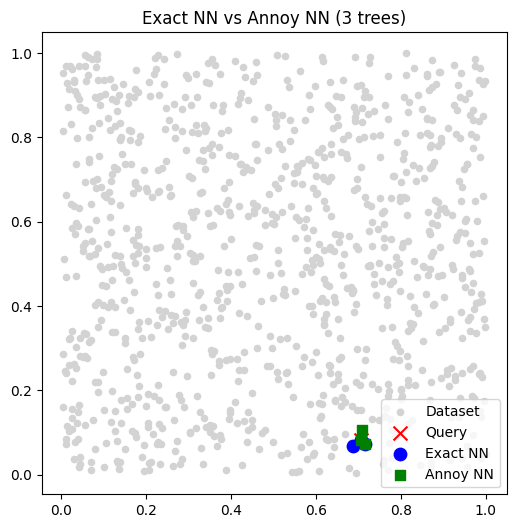

In [1]:
!pip install annoy

import numpy as np
import matplotlib.pyplot as plt
import time
from annoy import AnnoyIndex

# Build Random Dataset and Query Point
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2)
query = X[np.random.randint(0, n_points)]

# Compute Exact NN Using Brute Force
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

# ANNOY 3 Tree
f = 2
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)
t.build(3)

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")

# Visualize
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c='lightgray', s=20, label='Dataset')
plt.scatter(query[0], query[1], c='red', marker='x', s=100, label='Query')
plt.scatter(X[idx_exact,0], X[idx_exact,1], c='blue', s=80, label='Exact NN')
plt.scatter(X[idx_ann,0], X[idx_ann,1], c='green', s=50, marker='s', label='Annoy NN')
plt.legend()
plt.title('Exact NN vs Annoy NN (3 trees)')
plt.show()